# **📊 Day 7 Project: Sales Forecast AI – Predict Future Revenue Trends**
## 🧠 Problem:
Businesses run blind without accurate sales predictions.
This project helps a retailer predict monthly sales, enabling smarter inventory, marketing, and growth decisions.

In [1]:
import pandas as pd  
import numpy as np  
import matplotlib.pyplot as plt  
import seaborn as sns  
import datetime  

In [2]:
import os,pwd
os.getcwd()
os.chdir("../")
%pwd

'/home/sheshpal/Documents/ml_llmops_project/Data_science[4]-end-to-end/DataSciecne_Project_forcasting'

In [3]:
df = pd.read_csv('data/train.csv')  
store = pd.read_csv('data/store.csv')  
df = pd.merge(df, store, on='Store', how='left')  

/tmp/ipykernel_58031/4004035811.py:1: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('data/train.csv')


In [4]:
df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


### 3. Data Exploration

In [5]:
df.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 18 columns):
 #   Column                     Non-Null Count    Dtype  
---  ------                     --------------    -----  
 0   Store                      1017209 non-null  int64  
 1   DayOfWeek                  1017209 non-null  int64  
 2   Date                       1017209 non-null  object 
 3   Sales                      1017209 non-null  int64  
 4   Customers                  1017209 non-null  int64  
 5   Open                       1017209 non-null  int64  
 6   Promo                      1017209 non-null  int64  
 7   StateHoliday               1017209 non-null  object 
 8   SchoolHoliday              1017209 non-null  int64  
 9   StoreType                  1017209 non-null  object 
 10  Assortment                 1017209 non-null  object 
 11  CompetitionDistance        1014567 non-null  float64
 12  CompetitionOpenSinceMonth  693861 non-null   float64
 13  CompetitionO

In [6]:
df.describe() 

,Store,DayOfWeek,Sales,Customers,Open,Promo,SchoolHoliday,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear
count,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.014567e+06,693861.000000,693861.000000,1.017209e+06,509178.000000,509178.000000
mean,5.584297e+02,3.998341e+00,5.773819e+03,6.331459e+02,8.301067e-01,3.815145e-01,1.786467e-01,5.430086e+03,7.222866,2008.690228,5.005638e-01,23.269093,2011.752774
std,3.219087e+02,1.997391e+00,3.849926e+03,4.644117e+02,3.755392e-01,4.857586e-01,3.830564e-01,7.715324e+03,3.211832,5.992644,4.999999e-01,14.095973,1.662870
min,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.000000e+01,1.000000,1900.000000,0.000000e+00,1.000000,2009.000000
25%,2.800000e+02,2.000000e+00,3.727000e+03,4.050000e+02,1.000000e+00,0.000000e+00,0.000000e+00,7.100000e+02,4.000000,2006.000000,0.000000e+00,13.000000,2011.000000
50%,5.580000e+02,4.000000e+00,5.744000e+03,6.090000e+02,1.000000e+00,0.000000e+00,0.000000e+00,2.330000e+03,8.000000,2010.000000,1.000000e+00,22.000000,2012.000000
75%,8.380000e+02,6.000000e+00,7.856000e+03,8.370000e+02,1.000000e+00,1.000000e+00,0.000000e+00,6.890000e+03,10.000000,2013.000000,1.000000e+00,37.000000,2013.000000
max,1.115000e+03,7.000000e+00,4.155100e+04,7.388000e+03,1.000000e+00,1.000000e+00,1.000000e+00,7.586000e+04,12.000000,2015.000000,1.000000e+00,50.000000,2015.000000


In [7]:
df['Date'] = pd.to_datetime(df['Date'])  

In [8]:
df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [9]:
df['CompetitionDistance'].isnull().sum()

np.int64(2642)

In [12]:
new_data = df.copy()

In [ ]:
new_data['CompetitionDistance'].isnull().sum()

np.int64(2642)

In [15]:
new_data['CompetitionDistance']=new_data['CompetitionDistance'].fillna(new_data['CompetitionDistance'].std())
new_data['CompetitionDistance']

0           1270.0
1            570.0
2          14130.0
3            620.0
4          29910.0
            ...   
1017204     1900.0
1017205     1880.0
1017206     9260.0
1017207      870.0
1017208     5350.0
Name: CompetitionDistance, Length: 1017209, dtype: float64

In [16]:
new_data['CompetitionDistance'].isnull().sum()

np.int64(0)

In [19]:
for x in new_data.columns:
    value =new_data[x].isnull().sum()
    if value>=1 and type(new_data[x])==int:
        new_data[x]=new_data[x].fillna(new_data[x].std())
    else:
        pass




In [20]:
new_data.isnull().sum()

Store                             0
DayOfWeek                         0
Date                              0
Sales                             0
Customers                         0
Open                              0
Promo                             0
StateHoliday                      0
SchoolHoliday                     0
StoreType                         0
Assortment                        0
CompetitionDistance               0
CompetitionOpenSinceMonth         0
CompetitionOpenSinceYear          0
Promo2                            0
Promo2SinceWeek                   0
Promo2SinceYear                   0
PromoInterval                508031
dtype: int64

In [21]:
df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


### 4. Feature Engineering

In [9]:
df['Year'] = df['Date'].dt.year  
df['Month'] = df['Date'].dt.month  
df['Day'] = df['Date'].dt.day  
df['WeekOfYear'] = df['Date'].dt.isocalendar().week  
df['PromoInterval'] = df['PromoInterval'].fillna('')  

### 5. Visualization

Text(0.5, 1.0, 'Sales Trend for Store 1')

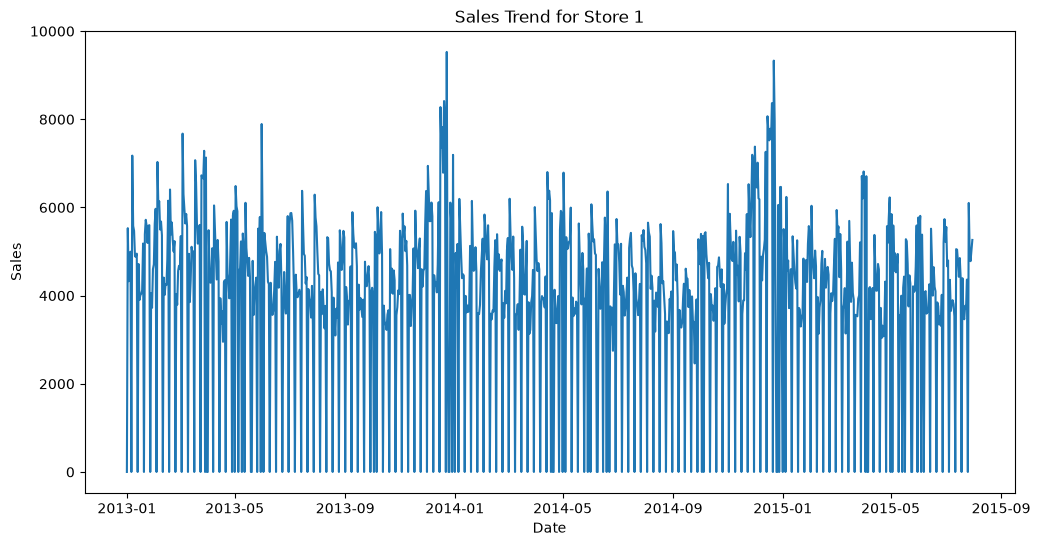

In [10]:
plt.figure(figsize=(12,6))  
sns.lineplot(data=df[df['Store']==1], x='Date', y='Sales')  
plt.title('Sales Trend for Store 1')  

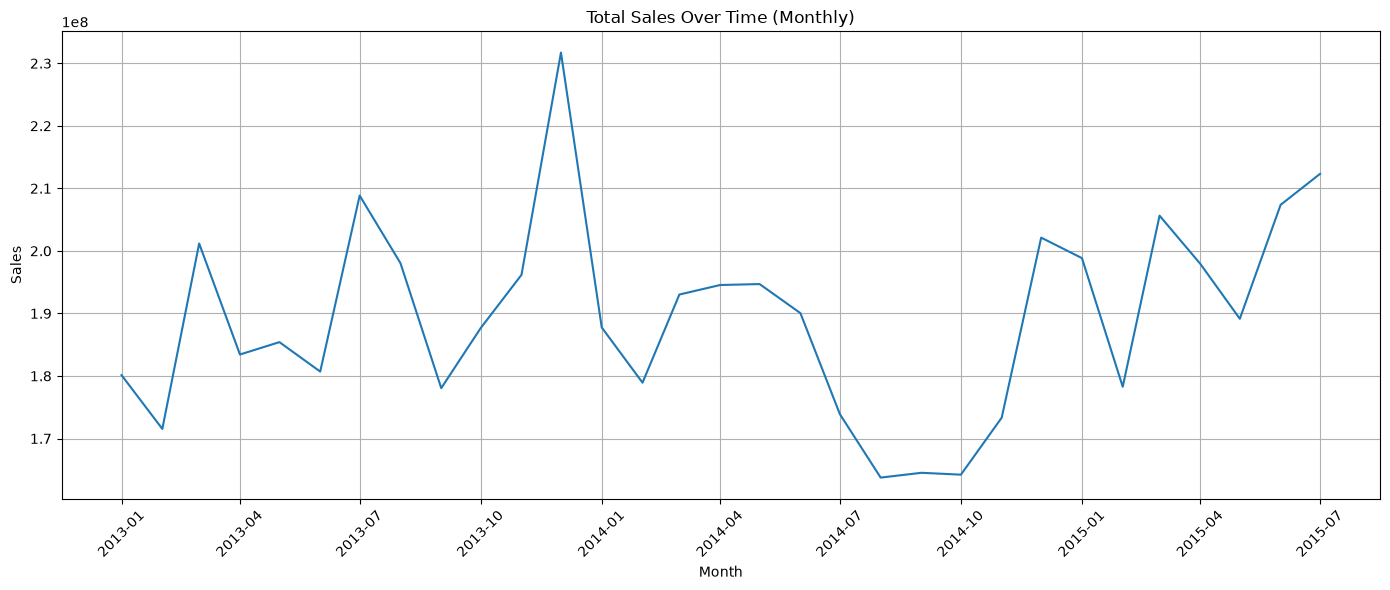

In [11]:
# Monthly Sales Trend
monthly_sales = df.groupby(['Year', 'Month'])['Sales'].sum().reset_index()
monthly_sales['Date'] = pd.to_datetime(monthly_sales[['Year', 'Month']].assign(DAY=1))

plt.figure(figsize=(14,6))
sns.lineplot(data=monthly_sales, x='Date', y='Sales')
plt.title("Total Sales Over Time (Monthly)")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

/tmp/ipykernel_54586/1693454867.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_stores.index, y=top_stores.values, palette='viridis')


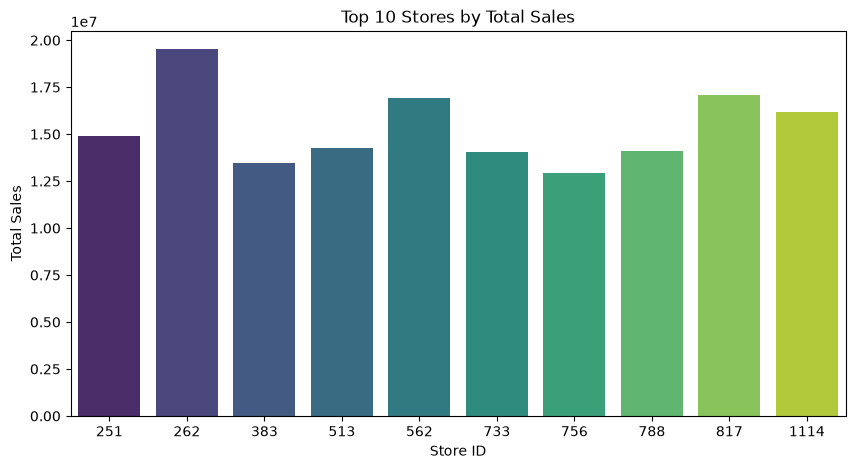

In [12]:
# Top 10 Best Performing Stores
top_stores = df.groupby('Store')['Sales'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,5))
sns.barplot(x=top_stores.index, y=top_stores.values, palette='viridis')
plt.title("Top 10 Stores by Total Sales")
plt.xlabel("Store ID")
plt.ylabel("Total Sales")
plt.show()

/tmp/ipykernel_54586/3708295656.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=dow_sales.index, y=dow_sales.values, palette='magma')


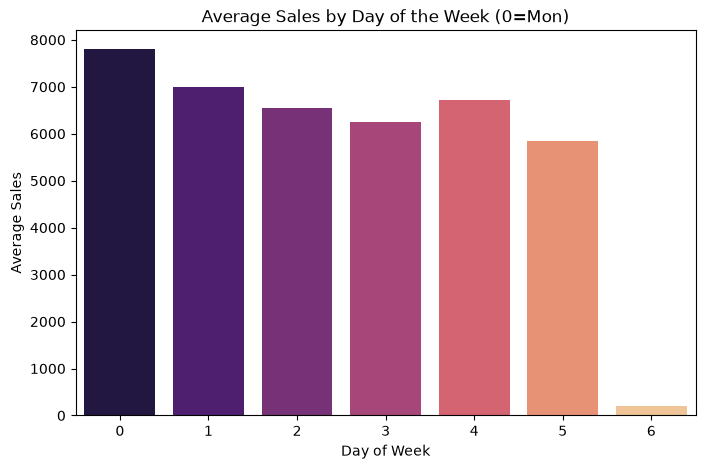

In [13]:
# Sales by Day of Week
df['DayOfWeek'] = df['Date'].dt.dayofweek
dow_sales = df.groupby('DayOfWeek')['Sales'].mean()

plt.figure(figsize=(8,5))
sns.barplot(x=dow_sales.index, y=dow_sales.values, palette='magma')
plt.title("Average Sales by Day of the Week (0=Mon)")
plt.xlabel("Day of Week")
plt.ylabel("Average Sales")
plt.show()

/tmp/ipykernel_54586/3817017791.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Promo', y='Sales', data=df, palette='coolwarm')


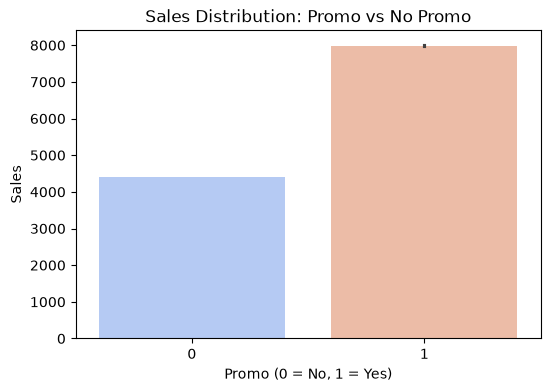

In [14]:
# Promo Impact on Sales
plt.figure(figsize=(6,4))
sns.barplot(x='Promo', y='Sales', data=df, palette='coolwarm')
plt.title("Sales Distribution: Promo vs No Promo")
plt.xlabel("Promo (0 = No, 1 = Yes)")
plt.ylabel("Sales")
plt.show()

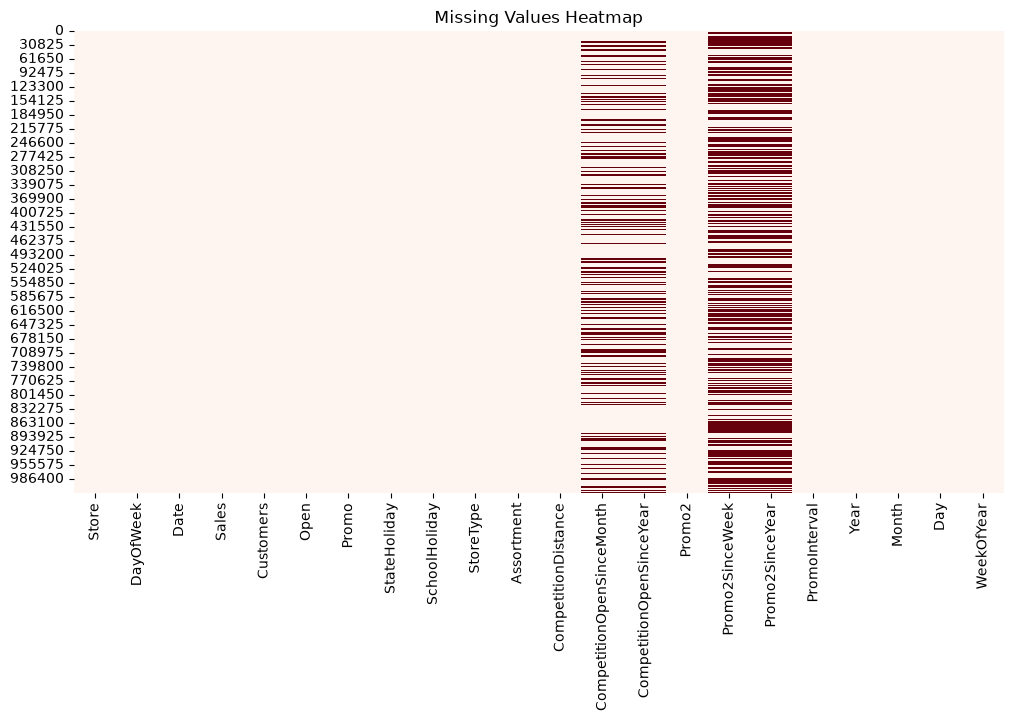

In [15]:
# Missing Data Heatmap
plt.figure(figsize=(12,6))
sns.heatmap(df.isnull(), cbar=False, cmap='Reds')
plt.title("Missing Values Heatmap")
plt.show()

In [22]:
df.isnull().sum()

Store                              0
DayOfWeek                          0
Date                               0
Sales                              0
Customers                          0
Open                               0
Promo                              0
StateHoliday                       0
SchoolHoliday                      0
StoreType                          0
Assortment                         0
CompetitionDistance          1017209
CompetitionOpenSinceMonth     323348
CompetitionOpenSinceYear      323348
Promo2                             0
Promo2SinceWeek               508031
Promo2SinceYear               508031
PromoInterval                      0
Year                               0
Month                              0
Day                                0
WeekOfYear                         0
dtype: int64

In [23]:
df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Year,Month,Day,WeekOfYear
0,1,4,2015-07-31,5263,555,1,1,0,1,c,...,9.0,2008.0,0,NaN,NaN,,2015,7,31,31
1,2,4,2015-07-31,6064,625,1,1,0,1,a,...,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct",2015,7,31,31
2,3,4,2015-07-31,8314,821,1,1,0,1,a,...,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",2015,7,31,31
3,4,4,2015-07-31,13995,1498,1,1,0,1,c,...,9.0,2009.0,0,NaN,NaN,,2015,7,31,31
4,5,4,2015-07-31,4822,559,1,1,0,1,a,...,4.0,2015.0,0,NaN,NaN,,2015,7,31,31


In [25]:
df['CompetitionDistance']

0          None
1          None
2          None
3          None
4          None
           ... 
1017204    None
1017205    None
1017206    None
1017207    None
1017208    None
Name: CompetitionDistance, Length: 1017209, dtype: object

In [21]:
df['CompetitionDistance']=df['CompetitionDistance'].fillna(df['CompetitionDistance'].mean(),inplace=True)
df['CompetitionDistance'].isnull().sum()

/tmp/ipykernel_54586/212061362.py:1: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['CompetitionDistance']=df['CompetitionDistance'].fillna(df['CompetitionDistance'].mean(),inplace=True)


np.int64(1017209)

### 6. Train-Test Split

In [16]:
from sklearn.model_selection import train_test_split  
from sklearn.ensemble import RandomForestRegressor  
from sklearn.metrics import mean_squared_error, r2_score  

X = df[['Store', 'Promo', 'SchoolHoliday', 'Year', 'Month', 'Day', 'WeekOfYear']]  
y = df['Sales']  

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)  

### 7. Model Training

In [17]:
model = RandomForestRegressor(n_estimators=100, random_state=42)  
model.fit(X_train, y_train)  

KeyboardInterrupt: 

### 8. Evaluation

In [ ]:
y_pred = model.predict(X_test)  
print("R2 Score:", r2_score(y_test, y_pred))  
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))  

R2 Score: 0.5763664768035746
RMSE: 2503.0041602325737


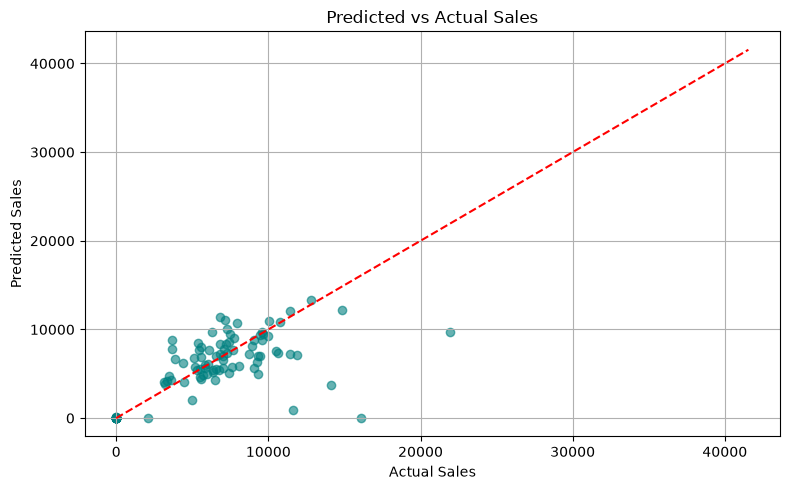

In [ ]:
# Predicted vs Actual
plt.figure(figsize=(8,5))
plt.scatter(y_test[:100], y_pred[:100], alpha=0.6, color='teal')
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Predicted vs Actual Sales")
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], '--', color='red')
plt.grid(True)
plt.tight_layout()
plt.show()